# Linear buckling analysis

The function [lb](../linear_buckling.rst) solves the linear buckling
eigenvalue problem

$$
(\boldsymbol{K} + \lambda \boldsymbol{K}_G) \boldsymbol{u} = \boldsymbol{0}
$$

for the load multipliers $\lambda$ and the buckling modes $\boldsymbol{u}$,
where $\boldsymbol{K}$ is the linear stiffness matrix and
$\boldsymbol{K}_G$ the geometric stiffness matrix of a reference load: the
critical load is $\lambda_1$ times the reference load. This example
verifies it on the column of rigid bars of Bathe (2014), Example 3.14, and
calculates the critical load of a simply supported plate under uniaxial
compression with a Ritz model, compared with the classical solution of
Timoshenko and Woinowsky-Krieger (1959).

**References.**

- Bathe, K.J., Finite Element Procedures, 2nd ed., K.J. Bathe, Watertown,
  MA, 2014.
- Castro, S.G.P. and Donadon, M.V., Assembly of semi-analytical models to
  address linear buckling and vibration of stiffened composite panels with
  debonding defect, Composite Structures, 160, 232-247, 2017.
  https://doi.org/10.1016/j.compstruct.2016.10.026
- Timoshenko, S. and Woinowsky-Krieger, S., Theory of Plates and Shells,
  2nd ed., McGraw-Hill, New York, 1959.

In [1]:
%matplotlib inline
import os
import sys

# the helper functions of the tests are imported from the folder tests/
sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import block_diag, csc_matrix
from scipy.special import roots_legendre

from structsolve import lb

from ritz import isotropic_plate, vecf, vecf_xi

## Column of two rigid bars

The column of Bathe's Example 3.14 is an assemblage of two rigid
weightless bars of length $L$, connected by frictionless pins, and springs
whose stiffnesses are proportional to $k$, under the axial load $P$ at its
free end. Its static
equilibrium equations are (Bathe 2014, Example 3.14, p. 101)

$$
k \begin{bmatrix} 5 & -2 \\ -2 & 2 \end{bmatrix}
\begin{Bmatrix} U_1 \\ U_2 \end{Bmatrix} = \frac{P}{L}
\begin{bmatrix} -2 & 1 \\ 1 & -1 \end{bmatrix}
\begin{Bmatrix} U_1 \\ U_2 \end{Bmatrix}
$$

with the critical load $P_{cr} = -2 k L$ (compression negative). With
$P = \lambda P_0$, the reference load $P_0 = -1$ and $L = 1$, they are
$(\boldsymbol{K} + \lambda \boldsymbol{K}_G) \boldsymbol{u} = \boldsymbol{0}$
with $\boldsymbol{K}$ the matrix on the left and $\boldsymbol{K}_G$ the
matrix on the right, and
$\det(\boldsymbol{K} + \lambda \boldsymbol{K}_G) = (2 k - \lambda)(3 k - \lambda)$
gives the load multipliers $\lambda = 2 k$, i.e. $P_{cr}$, and $3 k$.

The model below has five uncoupled copies of the column, with
$k = 1, 4, 16, 64, 256$, such that the sparse solver of
[lb](../linear_buckling.rst) computes the five lowest load multipliers of a
model of ten degrees of freedom:

In [2]:
k = 4.**np.arange(5)
K = block_diag([ki*np.array([[5., -2.], [-2., 2.]]) for ki in k])
KG = block_diag([np.array([[-2., 1.], [1., -1.]])]*5)

eigvals, eigvecs = lb(csc_matrix(K), csc_matrix(KG), silent=True,
                      num_eigvalues=5, sparse_solver=True)

ref = np.sort(np.concatenate((2*k, 3*k)))[:5]
print(f'{"mode":>4s} {"lambda (lb)":>14s} {"closed form":>12s} {"rel. diff.":>10s}')
for i in range(5):
    print(f'{i+1:4d} {eigvals[i]:14.10f} {ref[i]:12.1f}'
          f' {abs(eigvals[i] - ref[i])/ref[i]:10.1e}')
print()
print('critical load of the column k = 1: P_cr = lambda_1*P0 =',
      eigvals[0]*(-1.), ', Bathe: -2 k L =', -2.)

mode    lambda (lb)  closed form rel. diff.
   1   2.0000000000          2.0    1.3e-15
   2   3.0000000000          3.0    8.9e-16
   3   8.0000000000          8.0    3.3e-15
   4  12.0000000000         12.0    1.5e-14
   5  32.0000000000         32.0    3.6e-15

critical load of the column k = 1: P_cr = lambda_1*P0 = -2.0000000000000027 , Bathe: -2 k L = -2.0


## Simply supported plate: Ritz model

The plate of length $a$ (along $x$), width $b$ and thickness $h$, of an
isotropic material, is under the uniform compression $N_{xx}$ (force per
unit length, negative in compression). The first-order shear deformation
theory (FSDT) describes it with the deflection $w$ and the rotations
$\phi_x$, $\phi_y$, with the curvatures and the transverse shear strains

$$
\boldsymbol{\kappa} = \begin{Bmatrix} \phi_{x,x} \\ \phi_{y,y} \\
\phi_{x,y} + \phi_{y,x} \end{Bmatrix}, \qquad
\boldsymbol{\gamma} = \begin{Bmatrix} \gamma_{yz} \\ \gamma_{xz}
\end{Bmatrix} = \begin{Bmatrix} \phi_y + w_{,y} \\ \phi_x + w_{,x}
\end{Bmatrix}
$$

The linear stiffness matrix comes from the strain energy
$\frac{1}{2} \int_A (\boldsymbol{\kappa}^\top \boldsymbol{D}
\boldsymbol{\kappa} + \boldsymbol{\gamma}^\top \boldsymbol{A}_s
\boldsymbol{\gamma}) \,\mathrm{d}A$, with the bending stiffnesses
$D_{ij}$ and the transverse shear stiffnesses $A_{44}$, $A_{45}$, $A_{55}$,
here with the shear correction factor 5/6 (`isotropic_plate` of
`tests/ritz.py`). The geometric stiffness matrix comes from the work of the
membrane force on the deflection,
$\frac{1}{2} \int_A N_{xx} w_{,x}^2 \,\mathrm{d}A$, for the reference load
$\hat{N}_{xx} = -100$ N/m.

Each field is a sum of products of functions of the natural coordinates
$\xi = 2x/a - 1$ and $\eta = 2y/b - 1$, e.g.
$w = \sum_{i,j} c_{ij} f_i(\xi) g_j(\eta)$, with `m1` terms in $\xi$ and
`m2` terms in $\eta$, `N = 3 m1 m2` degrees of freedom. The functions are
the hierarchical Legendre-based functions of Bardell, as in Castro and
Donadon (2017), implemented with NumPy in `vecf` and `vecf_xi` of
`tests/ritz.py`: the first four are cubic Hermite functions, whose
displacement and rotation at $\xi = \pm 1$ are switched on or off by four
flags, the following ones vanish with their first derivative at both
ends. The deflection is null at the four edges and the rotations are free:
the simply supported plate. The matrices are integrated with Gauss-Legendre
quadrature. The function below is the model of the test
`test_lb_plate_buckling_fsdt` of `tests/test_linear_buckling.py`, for any
$a$, $b$, $h$:

In [3]:
def plate_matrices(a, b, h, E, nu, m1, m2, Nxxhat=-100.):
    # K and KG of the simply supported FSDT plate, dofs [w, phix, phiy]
    N = 3*m1*m2
    pts1, weights1 = roots_legendre(2*m1 - 1)
    pts2, weights2 = roots_legendre(2*m2 - 1)

    # BCs: w simply supported (displacement flags 0), phi free
    wxit1, wxir1, wxit2, wxir2 = 0, 1, 0, 1
    wetat1, wetar1, wetat2, wetar2 = 0, 1, 0, 1
    xit1, xir1, xit2, xir2 = 1, 1, 1, 1
    etat1, etar1, etat2, etar2 = 1, 1, 1, 1

    prop = isotropic_plate(thickness=h, E=E, nu=nu)

    Sw_x = np.zeros(N)
    Sw_y = np.zeros(N)
    Sphix = np.zeros(N)
    Sphiy = np.zeros(N)
    Sphix_x = np.zeros(N)
    Sphix_y = np.zeros(N)
    Sphiy_x = np.zeros(N)
    Sphiy_y = np.zeros(N)

    buff = np.zeros((N, N))
    K = np.zeros((N, N))
    KG = np.zeros((N, N))

    def addouter(matrix, vec1, vec2):
        np.outer(vec1, vec2, out=buff)
        matrix += buff

    detJ = a*b/4
    for xi, wxi in zip(pts1, weights1):
        wPxi = vecf(m1, xi, wxit1, wxir1, wxit2, wxir2)
        wPxi_xi = vecf_xi(m1, xi, wxit1, wxir1, wxit2, wxir2)
        Pxi = vecf(m1, xi, xit1, xir1, xit2, xir2)
        Pxi_xi = vecf_xi(m1, xi, xit1, xir1, xit2, xir2)

        for eta, weta in zip(pts2, weights2):
            wPeta = vecf(m2, eta, wetat1, wetar1, wetat2, wetar2)
            wPeta_eta = vecf_xi(m2, eta, wetat1, wetar1, wetat2, wetar2)
            Peta = vecf(m2, eta, etat1, etar1, etat2, etar2)
            Peta_eta = vecf_xi(m2, eta, etat1, etar1, etat2, etar2)

            weight = wxi*weta

            Pi, Pj = np.meshgrid(Pxi, Peta, indexing='ij')
            Sphix[m1*m2:2*m1*m2] = (Pi*Pj).flatten()
            Sphiy[2*m1*m2:] = (Pi*Pj).flatten()

            Pi_xi, Pj = np.meshgrid(wPxi_xi, wPeta, indexing='ij')
            Sw_x[:m1*m2] = (Pi_xi*Pj*(2/a)).flatten()

            Pi_xi, Pj = np.meshgrid(Pxi_xi, Peta, indexing='ij')
            Sphix_x[m1*m2:2*m1*m2] = (Pi_xi*Pj*(2/a)).flatten()
            Sphiy_x[2*m1*m2:] = (Pi_xi*Pj*(2/a)).flatten()

            Pi, Pj_eta = np.meshgrid(wPxi, wPeta_eta, indexing='ij')
            Sw_y[:m1*m2] = (Pi*Pj_eta*(2/b)).flatten()

            Pi, Pj_eta = np.meshgrid(Pxi, Peta_eta, indexing='ij')
            Sphix_y[m1*m2:2*m1*m2] = (Pi*Pj_eta*(2/b)).flatten()
            Sphiy_y[2*m1*m2:] = (Pi*Pj_eta*(2/b)).flatten()

            e1xx = Sphix_x
            e1yy = Sphiy_y
            e1xy = Sphix_y + Sphiy_x

            g0yz = Sphiy + Sw_y
            g0xz = Sphix + Sw_x

            Mxx = prop.D11*e1xx + prop.D12*e1yy + prop.D16*e1xy
            Myy = prop.D12*e1xx + prop.D22*e1yy + prop.D26*e1xy
            Mxy = prop.D16*e1xx + prop.D26*e1yy + prop.D66*e1xy

            Qy = prop.A44*g0yz + prop.A45*g0xz
            Qx = prop.A45*g0yz + prop.A55*g0xz

            addouter(K, detJ*weight*Mxx, e1xx)
            addouter(K, detJ*weight*Myy, e1yy)
            addouter(K, detJ*weight*Mxy, e1xy)
            addouter(K, detJ*weight*Qy, g0yz)
            addouter(K, detJ*weight*Qx, g0xz)

            addouter(KG, detJ*weight*Nxxhat*Sw_x, Sw_x)

    return csc_matrix(K), csc_matrix(KG)


def deflection(c, a, b, m1, m2, num=81):
    # w(x, y) of the eigenvector c on a grid
    xi = np.linspace(-1, 1, num)
    eta = np.linspace(-1, 1, num)
    f = vecf(m1, xi, 0, 1, 0, 1)    # shape (m1, num)
    g = vecf(m2, eta, 0, 1, 0, 1)   # shape (m2, num)
    C = c[:m1*m2].reshape(m1, m2)
    w = f.T @ C @ g                 # w[i, j] at xi[i], eta[j]
    x = (xi + 1)*a/2
    y = (eta + 1)*b/2
    return x, y, w

## Classical solution

For the simply supported plate under the uniform compression $N_x$, the
classical plate theory gives the critical load (Timoshenko and
Woinowsky-Krieger 1959, Section 93, Eq. (227), p. 389)

$$
(N_x)_{cr} = \frac{\pi^2 D}{b^2} \left(\frac{m b}{a} +
\frac{a}{m b}\right)^2, \qquad D = \frac{E h^3}{12 (1 - \nu^2)}
$$

minimized over the number $m$ of half-waves along $x$. For an integer
$a/b$, $m = a/b$ and $(N_x)_{cr} = 4 \pi^2 D/b^2$. The FSDT of the Ritz
model gives a slightly lower critical load, because of the transverse shear
deformation, which the classical theory neglects.

In [4]:
def Ncr_classical(a, b, h, E, nu):
    D = E*h**3/(12*(1 - nu**2))
    m = np.arange(1, 20)
    N = np.pi**2*D/b**2*(m*b/a + a/(m*b))**2
    return N.min(), m[N.argmin()]

## Critical loads

The steel plate of the test, $b = 0.1$ m, $h = 0.003$ m, $E = 200$ GPa,
$\nu = 0.3$, with `m1 = 20` and `m2 = 10` terms, for several aspect ratios
$a/b$, including the plate of the test, $a = 0.3$ m. The critical load is
$N_{cr} = \lambda_1 |\hat{N}_{xx}|$; the number of half-waves of the
buckling mode is counted from the sign changes of $w$ along the line
$y = b/2$:

In [5]:
E = 200.e9
nu = 0.3
b, h = 0.1, 0.003
m1, m2 = 20, 10
Nxxhat = -100.

results = []
for a_b in [1., 1.5, 2., 3.]:
    a = a_b*b
    K, KG = plate_matrices(a, b, h, E, nu, m1, m2, Nxxhat=Nxxhat)
    eigvals, eigvecs = lb(K, KG, silent=True)
    Ncr = eigvals[0]*abs(Nxxhat)
    x, y, w = deflection(eigvecs[:, 0].real, a, b, m1, m2)
    wc = w[:, w.shape[1]//2]
    wc = wc[np.abs(wc) > 1e-8*np.abs(wc).max()]
    m_ritz = np.count_nonzero(np.diff(np.sign(wc))) + 1
    Nref, m_ref = Ncr_classical(a, b, h, E, nu)
    results.append((a_b, Ncr, m_ritz, Nref, m_ref, (a, eigvecs[:, 0].real)))

print(f'{"a/b":>4s} {"N_cr Ritz FSDT":>15s} {"m":>3s} {"Eq. (227)":>12s}'
      f' {"m":>3s} {"rel. diff.":>10s}   (N/m)')
for a_b, Ncr, m_ritz, Nref, m_ref, _ in results:
    print(f'{a_b:4.1f} {Ncr:15.1f} {m_ritz:3d} {Nref:12.1f} {m_ref:3d}'
          f' {(Ncr - Nref)/Nref:10.2e}')

 a/b  N_cr Ritz FSDT   m    Eq. (227)   m rel. diff.   (N/m)
 1.0       1899719.4   1    1952229.4   1  -2.69e-02
 1.5       2069319.6   2    2118304.5   2  -2.31e-02
 2.0       1912480.5   2    1952229.4   2  -2.04e-02
 3.0       1917554.2   3    1952229.4   3  -1.78e-02


The Ritz model gives the number of half-waves of Eq. (227), and critical
loads between 1.8 % and 2.7 % lower than the classical ones, as expected
from the transverse shear deformation of the FSDT. These values are those
of `m1 = 20` and `m2 = 10` terms, the model of the test. The buckling mode of the plate of the test, $a/b = 3$, has
three half-waves along $x$:

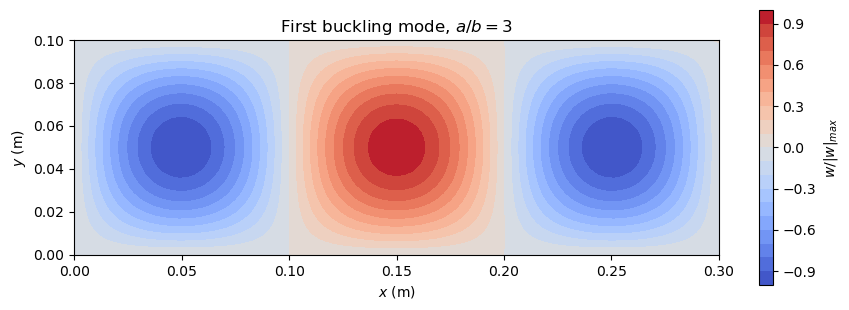

In [6]:
a, c = results[-1][-1]
x, y, w = deflection(c, a, b, m1, m2)
w = w/np.abs(w).max()
fig, ax = plt.subplots(figsize=(9, 3.2))
cs = ax.contourf(x, y, w.T, levels=21, cmap='coolwarm')
fig.colorbar(cs, ax=ax, label='$w/|w|_{max}$')
ax.set_aspect('equal')
ax.set_xlabel('$x$ (m)')
ax.set_ylabel('$y$ (m)')
ax.set_title('First buckling mode, $a/b = 3$')
plt.tight_layout()
plt.show()